TASK A (Spatial Networks and Planarity)

In this task, we analyse the road network of Leeds along with accident data to identify a suitable study area. The area is selected based on the concentration of road traffic accidents across multiple years to ensure meaningful spatial analysis.

Loading Accident Data with Correct Encoding - The accident datasets are encoded using a non-UTF-8 format, which can cause decoding errors when loading the data. To address this, the files are read using the appropriate encoding to ensure all characters are interpreted correctly.

In [3]:
import pandas as pd

# load datasets
df14 = pd.read_csv("../../data/raw/accidents_2014.csv", encoding='latin-1')
df15 = pd.read_csv("../../data/raw/accidents_2015.csv", encoding='latin-1')
df16 = pd.read_csv("../../data/raw/accidents_2016.csv", encoding='latin-1')

# merge
accidents = pd.concat([df14, df15, df16], ignore_index=True)

print("Total accidents:", len(accidents))
accidents.head()

Total accidents: 7746


,Reference Number,Grid Ref: Easting,Grid Ref: Northing,Number of Vehicles,Accident Date,Time (24hr),1st Road Class,Road Surface,Lighting Conditions,Weather Conditions,Casualty Class,Unnamed: 11,Casualty Severity,Sex of Casualty,Age of Casualty,Type of Vehicle,Expr1
0,1112091,429175,431904,2,01-Jan-14,1840,Unclassified,Wet / Damp,Darkness: street lights present and lit,Raining without high winds,1,Driver,Slight,Male,58,Car,NaN
1,1180869,430429,431025,3,08-Jan-14,1430,Motorway,Wet / Damp,Daylight: street lights present,Fine without high winds,1,Driver,Slight,Male,69,Car,NaN
2,1180869,430429,431025,3,08-Jan-14,1430,Motorway,Wet / Damp,Daylight: street lights present,Fine without high winds,1,Driver,Slight,Female,41,Car,NaN
3,11A0238,424660,427582,3,10-Jan-14,817,Motorway,Dry,Daylight: street lights present,Fine without high winds,1,Driver,Slight,Male,35,Car,NaN
4,11A0238,424660,427582,3,10-Jan-14,817,Motorway,Dry,Daylight: street lights present,Fine without high winds,1,Driver,Slight,Male,25,Car,NaN


The datasets are successfully loaded using the correct encoding, allowing further processing and integration of multiple years of accident data for analysis.

Converting Accident Data to Spatial Representation - The accident dataset includes spatial information in the form of Easting and Northing coordinates, which are based on the British National Grid system. To enable spatial analysis, these coordinates are converted into geometric point representations using a GeoDataFrame.
This transformation allows the accident data to be visualised and analysed in geographic space.

In [5]:
import geopandas as gpd
from shapely.geometry import Point

# create geometry column
geometry = [
    Point(xy) for xy in zip(accidents['Grid Ref: Easting'], accidents['Grid Ref: Northing'])
]

gdf = gpd.GeoDataFrame(accidents, geometry=geometry)

gdf.head()

,Reference Number,Grid Ref: Easting,Grid Ref: Northing,Number of Vehicles,Accident Date,Time (24hr),1st Road Class,Road Surface,Lighting Conditions,Weather Conditions,Casualty Class,Unnamed: 11,Casualty Severity,Sex of Casualty,Age of Casualty,Type of Vehicle,Expr1,geometry
0,1112091,429175,431904,2,01-Jan-14,1840,Unclassified,Wet / Damp,Darkness: street lights present and lit,Raining without high winds,1,Driver,Slight,Male,58,Car,NaN,POINT (429175 431904)
1,1180869,430429,431025,3,08-Jan-14,1430,Motorway,Wet / Damp,Daylight: street lights present,Fine without high winds,1,Driver,Slight,Male,69,Car,NaN,POINT (430429 431025)
2,1180869,430429,431025,3,08-Jan-14,1430,Motorway,Wet / Damp,Daylight: street lights present,Fine without high winds,1,Driver,Slight,Female,41,Car,NaN,POINT (430429 431025)
3,11A0238,424660,427582,3,10-Jan-14,817,Motorway,Dry,Daylight: street lights present,Fine without high winds,1,Driver,Slight,Male,35,Car,NaN,POINT (424660 427582)
4,11A0238,424660,427582,3,10-Jan-14,817,Motorway,Dry,Daylight: street lights present,Fine without high winds,1,Driver,Slight,Male,25,Car,NaN,POINT (424660 427582)


The accident dataset is successfully converted into a GeoDataFrame, where each accident is represented as a spatial point. This enables geographic operations such as plotting, filtering, and identifying high-density regions.

Visualising Accident Distribution - To identify areas with a high concentration of accidents, the spatial distribution of accident points is visualised. This helps in selecting a study area that satisfies the requirement of containing a significant number of accidents.

<Figure size 600x600 with 0 Axes>

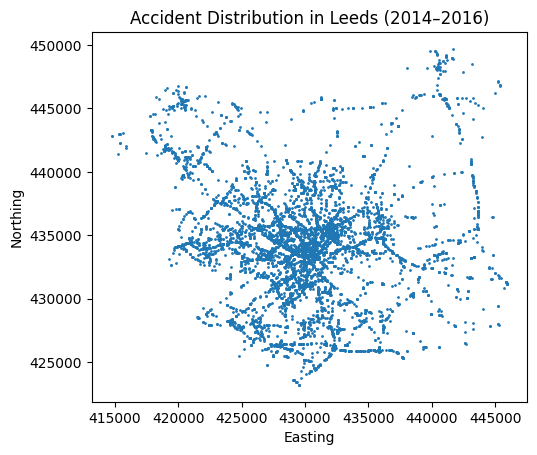

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,6))
gdf.plot(markersize=1)

plt.title("Accident Distribution in Leeds (2014–2016)")
plt.xlabel("Easting")
plt.ylabel("Northing")
plt.show()

The spatial distribution plot reveals regions with higher concentrations of accidents. These dense clusters indicate areas of increased traffic activity and are used to guide the selection of the study area.

Selecting a High-Density Study Area :

A candidate study area of approximately 1 km² is defined using a bounding box around a central point. The number of accidents within this area is calculated to verify that it satisfies the requirement of containing at least 300 accidents.

In [7]:
# choose a center manually (we refine if needed)
center_easting = gdf['Grid Ref: Easting'].median()
center_northing = gdf['Grid Ref: Northing'].median()

# define 1 km² box (±500m)
buffer = 500

subset = gdf[
    (gdf['Grid Ref: Easting'] >= center_easting - buffer) &
    (gdf['Grid Ref: Easting'] <= center_easting + buffer) &
    (gdf['Grid Ref: Northing'] >= center_northing - buffer) &
    (gdf['Grid Ref: Northing'] <= center_northing + buffer)
]

print("Accidents in selected area:", len(subset))

Accidents in selected area: 178


Identifying a High-Density Accident Region:

To ensure that the selected study area contains a sufficient number of accidents, a grid-based search is performed. The study region is divided into candidate areas, and the number of accidents within each is evaluated to identify the densest region.

In [8]:
import numpy as np

# define grid size (1.1km = 1000m)
grid_size = 1100

max_count = 0
best_box = None

eastings = gdf['Grid Ref: Easting']
northings = gdf['Grid Ref: Northing']

# scan grid
for x in np.arange(eastings.min(), eastings.max(), 500):
    for y in np.arange(northings.min(), northings.max(), 500):
        
        subset = gdf[
            (eastings >= x) & (eastings <= x + grid_size) &
            (northings >= y) & (northings <= y + grid_size)
        ]
        
        if len(subset) > max_count:
            max_count = len(subset)
            best_box = (x, y)

print("Max accidents found:", max_count)
print("Best box corner:", best_box)

Max accidents found: 354
Best box corner: (np.int64(429745), np.int64(433187))


Final Study Area Definition:

The study area is defined as a square region of approximately 1 km², refined to ensure that it contains a sufficient number of accidents. The selected region corresponds to the area with the highest observed accident density across the dataset.

In [9]:
# use best box from grid search
x, y = best_box
grid_size = 1100  # final chosen size

final_area = gdf[
    (eastings >= x) & (eastings <= x + grid_size) &
    (northings >= y) & (northings <= y + grid_size)
]

print("Final accident count:", len(final_area))

Final accident count: 354


The selected study area contains 354 accidents, satisfying the requirement of at least 300 incidents. This confirms that the chosen region represents a high-density accident area suitable for spatial and network analysis.

Converting Coordinates to Latitude and Longitude:

The accident data is represented using British National Grid coordinates (Easting and Northing). To integrate this with OpenStreetMap data, the coordinates are transformed into latitude and longitude using an appropriate coordinate reference system conversion.

In [10]:
# set CRS (British National Grid)
gdf.set_crs(epsg=27700, inplace=True)

# convert to lat/long
gdf_latlon = gdf.to_crs(epsg=4326)

gdf_latlon.head()

,Reference Number,Grid Ref: Easting,Grid Ref: Northing,Number of Vehicles,Accident Date,Time (24hr),1st Road Class,Road Surface,Lighting Conditions,Weather Conditions,Casualty Class,Unnamed: 11,Casualty Severity,Sex of Casualty,Age of Casualty,Type of Vehicle,Expr1,geometry
0,1112091,429175,431904,2,01-Jan-14,1840,Unclassified,Wet / Damp,Darkness: street lights present and lit,Raining without high winds,1,Driver,Slight,Male,58,Car,NaN,POINT (-1.55872 53.78267)
1,1180869,430429,431025,3,08-Jan-14,1430,Motorway,Wet / Damp,Daylight: street lights present,Fine without high winds,1,Driver,Slight,Male,69,Car,NaN,POINT (-1.53977 53.77469)
2,1180869,430429,431025,3,08-Jan-14,1430,Motorway,Wet / Damp,Daylight: street lights present,Fine without high winds,1,Driver,Slight,Female,41,Car,NaN,POINT (-1.53977 53.77469)
3,11A0238,424660,427582,3,10-Jan-14,817,Motorway,Dry,Daylight: street lights present,Fine without high winds,1,Driver,Slight,Male,35,Car,NaN,POINT (-1.62758 53.74405)
4,11A0238,424660,427582,3,10-Jan-14,817,Motorway,Dry,Daylight: street lights present,Fine without high winds,1,Driver,Slight,Male,25,Car,NaN,POINT (-1.62758 53.74405)



The coordinate transformation enables compatibility with OpenStreetMap data, allowing the selected study area to be used for extracting the road network and performing spatial analysis.

Determining Study Area Coordinates:

The center point of the selected study area is calculated and converted into latitude and longitude. These coordinates are used both for reporting and for extracting the corresponding road network.

In [11]:
# convert best box center to lat/long
center_easting = x + grid_size / 2
center_northing = y + grid_size / 2

center_point = gpd.GeoSeries(
    [Point(center_easting, center_northing)],
    crs="EPSG:27700"
).to_crs(epsg=4326)

center_lat = center_point.geometry.y.values[0]
center_lon = center_point.geometry.x.values[0]

print("Center coordinates:", center_lat, center_lon)

Center coordinates: 53.799076666971224 -1.5415405930521162


The computed coordinates define the location of the study area within Leeds and provide the reference point for extracting the road network.

Defining the Study Area Boundaries:

In addition to the centre point, the full spatial extent of the selected study area is recorded. This makes the area definition reproducible and provides the coordinates required for reporting.

In [12]:
# study area boundaries in British National Grid
min_easting = x
max_easting = x + grid_size
min_northing = y
max_northing = y + grid_size

print("Study area boundaries (BNG):")
print("Easting :", min_easting, "to", max_easting)
print("Northing:", min_northing, "to", max_northing)
print("Center (lat, lon):", center_lat, center_lon)

Study area boundaries (BNG):
Easting : 429745 to 430845
Northing: 433187 to 434287
Center (lat, lon): 53.799076666971224 -1.5415405930521162


The selected study area is therefore defined both by its centre coordinates and by its Easting/Northing bounds. This gives a clear and reproducible specification of the approximately 1 km² area used in the analysis.

Extracting the Road Network:

The road network corresponding to the selected study area is extracted using OpenStreetMap via the OSMnx library. Only roads suitable for driving are included, as required by the task, by specifying the appropriate network type filter.

In [14]:
import osmnx as ox

# use center from previous step
coords = (center_lat, center_lon)

# approximate radius (half of ~1km² area)
dist = 550  # slightly adjusted for ~1100m box

G = ox.graph_from_point(
    coords,
    dist=dist,
    network_type='drive'
)

# project graph for accurate distance calculations
G_proj = ox.project_graph(G)

G_proj

The extracted network represents the road structure within the selected study area. The filtering ensures that only roads accessible to vehicles are included, excluding pedestrian paths and private roads.

Preparing Graph for Analysis:

Before computing network metrics, the graph is converted into an undirected version and basic structural properties are extracted. This ensures compatibility with graph algorithms such as diameter calculation.

In [15]:
import networkx as nx

# convert to undirected graph (IMPORTANT FIX)
G_undirected = G_proj.to_undirected()

# basic counts
num_nodes = G_undirected.number_of_nodes()
num_edges = G_undirected.number_of_edges()

print("Nodes:", num_nodes)
print("Edges:", num_edges)

# compute stats
stats = ox.basic_stats(G_proj)

stats

Nodes: 211
Edges: 295


{'n': 211,
 'm': 359,
 'k_avg': 3.4028436018957344,
 'edge_length_total': 24193.515910127855,
 'edge_length_avg': 67.39140922041186,
 'streets_per_node_avg': 2.990521327014218,
 'streets_per_node_counts': {0: 0, 1: 14, 2: 14, 3: 145, 4: 36, 5: 2},
 'streets_per_node_proportions': {0: 0.0,
  1: 0.06635071090047394,
  2: 0.06635071090047394,
  3: 0.6872037914691943,
  4: 0.17061611374407584,
  5: 0.009478672985781991},
 'intersection_count': 197,
 'street_length_total': 19579.450100134894,
 'street_segment_count': 296,
 'street_length_avg': 66.1467908788341,
 'circuity_avg': 1.073683686519192,
 'self_loop_proportion': 0.0033783783783783786}

The graph is converted to an undirected representation to enable computation of structural metrics such as diameter. The node and edge counts provide a basic description of the network size.

Calculating Density Measures:

To quantify how concentrated the road network is within the study area, density measures are computed manually. This ensures consistency and avoids reliance on library-specific outputs.

In [16]:
# area of study region (~1.1 km × 1.1 km)
area_km2 = (grid_size / 1000) ** 2

node_density = num_nodes / area_km2
edge_density = num_edges / area_km2

avg_street_length = stats['street_length_avg']


print("Average street length:", avg_street_length)
print("Node density:", node_density)
print("Edge density:", edge_density)

Average street length: 66.1467908788341
Node density: 174.38016528925618
Edge density: 243.80165289256195


The density measures are calculated manually using the size of the study area. This provides a consistent and transparent way to quantify how densely connected the network is, independent of library-specific implementations.

Calculating Intersection Density - Intersection density measures how frequently roads intersect within the study area. It is computed by identifying nodes with degree greater than two, which represent junctions where multiple roads meet.

In [17]:
# intersection nodes (degree > 2)
intersection_nodes = [n for n, d in G_undirected.degree() if d > 2]

intersection_density = len(intersection_nodes) / area_km2

print("Intersection density:", intersection_density)

Intersection density: 130.5785123966942


The intersection density indicates the level of connectivity within the road network. Higher values correspond to dense urban areas with frequent junctions, while lower values indicate more sparse or hierarchical road structures.

Calculating Spatial Diameter:

The spatial diameter is the greatest shortest-path distance within the road network when road lengths are taken into account. Since road networks may contain disconnected parts, this is computed on the largest connected component of the undirected graph.

In [18]:
# largest connected component
largest_cc = max(nx.connected_components(G_undirected), key=len)
G_lcc = G_undirected.subgraph(largest_cc).copy()

# spatial diameter: maximum weighted shortest-path distance
all_lengths = dict(nx.all_pairs_dijkstra_path_length(G_lcc, weight="length"))
spatial_diameter = max(max(lengths.values()) for lengths in all_lengths.values())

print("Spatial diameter (metres):", spatial_diameter)
print("Spatial diameter (km):", spatial_diameter / 1000)

Spatial diameter (metres): 2925.227463997006
Spatial diameter (km): 2.925227463997006


The spatial diameter measures the longest shortest travel distance across the main connected part of the road network. Unlike a simple hop-based diameter, this metric reflects the actual physical extent of the network in metres.

Calculating Average Circuitry - 

Average circuitry compares network travel distance to straight-line distance between points. It is used to evaluate how direct movement through the road network is. Values close to 1 indicate efficient, direct routes, while larger values indicate more circuitous travel.

In [19]:
import random
import numpy as np

# make the random sampling reproducible
random.seed(42)

nodes = list(G_lcc.nodes())
sample_size = min(100, len(nodes))
sampled_nodes = random.sample(nodes, sample_size)

circuity_ratios = []

for i in range(len(sampled_nodes) - 1):
    u = sampled_nodes[i]
    v = sampled_nodes[i + 1]

    try:
        # shortest road distance
        road_dist = nx.shortest_path_length(G_lcc, source=u, target=v, weight="length")

        # straight-line distance using projected coordinates
        x1, y1 = G_lcc.nodes[u]["x"], G_lcc.nodes[u]["y"]
        x2, y2 = G_lcc.nodes[v]["x"], G_lcc.nodes[v]["y"]
        euclidean_dist = ((x1 - x2)**2 + (y1 - y2)**2) ** 0.5

        if euclidean_dist > 0:
            circuity_ratios.append(road_dist / euclidean_dist)

    except nx.NetworkXNoPath:
        continue

average_circuity = np.mean(circuity_ratios)

print("Average circuitry:", average_circuity)

Average circuitry: 1.6551372061302108


The average circuitry indicates how direct travel is within the network. A value only slightly above 1 suggests relatively efficient travel, whereas higher values indicate that routes are less direct because of the street layout, junction structure, or movement constraints.

Testing Planarity:

A planar graph can be drawn on a 2D plane without edges crossing. For street networks, this condition is often violated because bridges, tunnels, and multi-level junctions create edge crossings without true intersections. A graph-theoretic planarity test is therefore used as an initial check.

In [20]:
is_planar, embedding = nx.check_planarity(G_undirected)

print("Is the road network planar?", is_planar)

Is the road network planar? True


The planarity test provides a graph-theoretic indication of whether the road network can be represented without crossing edges. In practice, real urban road networks often fail this condition because grade-separated roads introduce crossings that are not true junctions.

Looking for Evidence of Non-Planarity:

To support the planarity discussion, the network is visually inspected for major roads, overpasses, or junction structures that could produce edge crossings without intersections. This helps connect the graph-theoretic result to the real road layout.

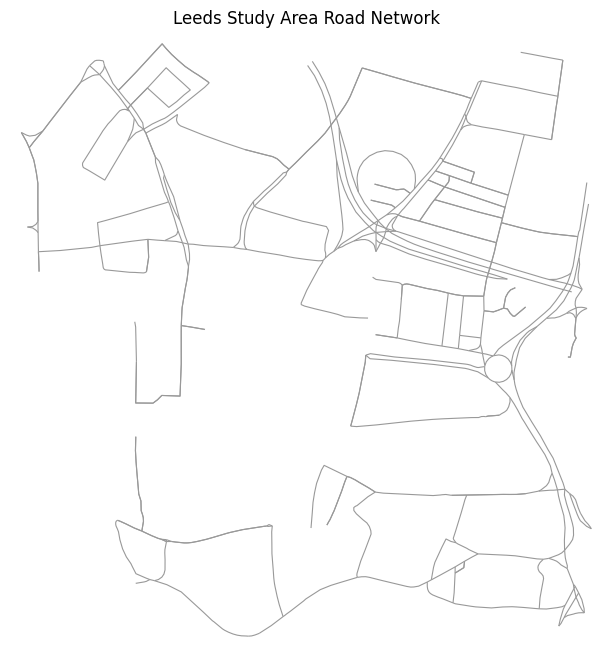

In [21]:
fig, ax = ox.plot_graph(
    G_proj,
    node_size=0,
    edge_linewidth=0.8,
    bgcolor="white",
    show=False,
    close=False
)

ax.set_title("Leeds Study Area Road Network")
plt.show()

The visual inspection can be used to identify plausible sources of non-planarity, such as major roads passing over or under local roads. These structures create apparent crossings in a 2D representation without corresponding nodes of intersection.

Summarising the Results:

The main quantitative outputs for Task A are gathered into a single summary table so that the study area and its road network characteristics can be referenced consistently in the report.

In [22]:
taskA_summary = pd.DataFrame({
    "Metric": [
        "Final accident count",
        "Center latitude",
        "Center longitude",
        "Min Easting",
        "Max Easting",
        "Min Northing",
        "Max Northing",
        "Number of nodes",
        "Number of edges",
        "Average street length (m)",
        "Node density (per km²)",
        "Edge density (per km²)",
        "Intersection density (per km²)",
        "Spatial diameter (m)",
        "Average circuitry",
        "Planar?"
    ],
    "Value": [
        len(final_area),
        center_lat,
        center_lon,
        min_easting,
        max_easting,
        min_northing,
        max_northing,
        num_nodes,
        num_edges,
        avg_street_length,
        node_density,
        edge_density,
        intersection_density,
        spatial_diameter,
        average_circuity,
        is_planar
    ]
})

taskA_summary

,Metric,Value
0,Final accident count,354
1,Center latitude,53.799077
2,Center longitude,-1.541541
3,Min Easting,429745
4,Max Easting,430845
5,Min Northing,433187
6,Max Northing,434287
7,Number of nodes,211
8,Number of edges,295
9,Average street length (m),66.146791


The summary table consolidates the key outputs required to answer Task A. These values will form the basis of the report discussion on study area selection, road-network structure, travel efficiency, and planarity.